In [ ]:
import pandas as pd # Импортируем библиотеку для работы с таблицами (датафреймами)
import matplotlib.pyplot as plt # Импортируем библиотеку для построения графиков
import seaborn as sns # Импортируем библиотеку для более красивой визуализации
from scipy.stats import chi2_contingency, fisher_exact # Импортируем инструменты для статистических тестов


In [ ]:
# 1. ЗАГРУЗКА ДАННЫХ
# Эмулируем два датасета из одного файла, скачивая разные колонки (чтобы показать merge и join)
data = pd.read_csv('tmdb_5000_movies.csv', usecols=['id', 'title', 'budget', 'revenue', 'status'])
data2 = pd.read_csv('tmdb_5000_movies.csv', usecols=['id', 'runtime', 'original_language', 'vote_average'])


In [ ]:
data.head(10) # Показываем первые 10 строк

,budget,id,revenue,status,title
0,237000000,19995,2787965087,Released,Avatar
1,300000000,285,961000000,Released,Pirates of the Caribbean: At World's End
2,245000000,206647,880674609,Released,Spectre
3,250000000,49026,1084939099,Released,The Dark Knight Rises
4,260000000,49529,284139100,Released,John Carter
5,258000000,559,890871626,Released,Spider-Man 3
6,260000000,38757,591794936,Released,Tangled
7,280000000,99861,1405403694,Released,Avengers: Age of Ultron
8,250000000,767,933959197,Released,Harry Potter and the Half-Blood Prince
9,250000000,209112,873260194,Released,Batman v Superman: Dawn of Justice


In [ ]:
data.tail(10) # Показываем последние 10 строк

,budget,id,revenue,status,title
4793,0,182291,0,Released,On The Downlow
4794,0,286939,0,Released,Sanctuary: Quite a Conundrum
4795,0,124606,0,Released,Bang
4796,7000,14337,424760,Released,Primer
4797,0,67238,0,Released,Cavite
4798,220000,9367,2040920,Released,El Mariachi
4799,9000,72766,0,Released,Newlyweds
4800,0,231617,0,Released,"Signed, Sealed, Delivered"
4801,0,126186,0,Released,Shanghai Calling
4802,0,25975,0,Released,My Date with Drew


In [ ]:
print(f"количество записей в датасете: {len(data)}") # Выводим общее количество строк в таблице

количество записей в датасете: 4803


In [ ]:
data.info() # Смотрим общую информацию: типы колонок и количество непустых значений

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   budget   4803 non-null   int64 
 1   id       4803 non-null   int64 
 2   revenue  4803 non-null   int64 
 3   status   4803 non-null   object
 4   title    4803 non-null   object
dtypes: int64(3), object(2)
memory usage: 187.7+ KB


In [ ]:
data.dtypes # Выводим только типы данных каждого столбца

,0
budget,int64
id,int64
revenue,int64
status,object
title,object


In [ ]:
data.columns # Выводим список названий всех столбцов

Index(['budget', 'id', 'revenue', 'status', 'title'], dtype='object')

In [ ]:
data.describe() # Считаем статистику (среднее, минимум, максимум) для числовых колонок

,budget,id,revenue
count,4.803000e+03,4803.000000,4.803000e+03
mean,2.904504e+07,57165.484281,8.226064e+07
std,4.072239e+07,88694.614033,1.628571e+08
min,0.000000e+00,5.000000,0.000000e+00
25%,7.900000e+05,9014.500000,0.000000e+00
50%,1.500000e+07,14629.000000,1.917000e+07
75%,4.000000e+07,58610.500000,9.291719e+07
max,3.800000e+08,459488.000000,2.787965e+09


In [ ]:
d = data.copy() # Создаем копию датасета

In [ ]:
d['status'] = d['status'].astype('category') # Меняем тип столбца на категориальный

In [ ]:
d['status'].cat.categories # Просматриваем список получившихся категорий

Index(['Post Production', 'Released', 'Rumored'], dtype='object')

In [ ]:
d.head() # Проверяем результат

,budget,id,revenue,status,title
0,237000000,19995,2787965087,Released,Avatar
1,300000000,285,961000000,Released,Pirates of the Caribbean: At World's End
2,245000000,206647,880674609,Released,Spectre
3,250000000,49026,1084939099,Released,The Dark Knight Rises
4,260000000,49529,284139100,Released,John Carter


In [ ]:
data['status'].unique() # Получаем список уникальных статусов

array(['Released', 'Post Production', 'Rumored'], dtype=object)

In [ ]:
data['status'].value_counts() # Считаем, сколько раз встречается каждый статус

,count
status,
Released,4795
Rumored,5
Post Production,3


In [ ]:
data2.head() # Изучаем начало второго датасета

,id,original_language,runtime,vote_average
0,19995,en,162.0,7.2
1,285,en,169.0,6.9
2,206647,en,148.0,6.3
3,49026,en,165.0,7.6
4,49529,en,132.0,6.1


In [ ]:
data2.info() # Смотрим информацию по второму датасету

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4803 non-null   int64  
 1   original_language  4803 non-null   object 
 2   runtime            4801 non-null   float64
 3   vote_average       4803 non-null   float64
dtypes: float64(2), int64(1), object(1)
memory usage: 150.2+ KB


In [ ]:
# 3. ИЗМЕНЕНИЕ СТРУКТУРЫ ДАТАСЕТА
data2.set_index('id', inplace=True) # Временно делаем колонку 'id' индексом (заменяем 0, 1, 2...)
#inplace=true - примени для этой таблицы а не создавай новую

In [ ]:
data2.head() # Проверяем

,original_language,runtime,vote_average
id,,,
19995,en,162.0,7.2
285,en,169.0,6.9
206647,en,148.0,6.3
49026,en,165.0,7.6
49529,en,132.0,6.1


In [ ]:
data2.loc[5, 'runtime'] # Ищем значение длительности по индексу (например, id = 5)

np.float64(98.0)

In [ ]:
data2.iloc[0, 0] # Вытягиваем конкретную ячейку по номеру строки и столбца

'en'

In [ ]:
data2.reset_index(inplace=True) # Сбрасываем 'id' обратно в обычную колонку

In [ ]:
data.drop('status', axis=1, inplace=True) # Удаляем столбец 'status' (axis=1 означает столбцы)

In [ ]:
data.drop(index=0, inplace=True) # Удаляем первую строку с индексом 0

In [ ]:
df_concat_rows = pd.concat([data, data], axis=0, ignore_index=True) # Склеиваем таблицы в длину (одна под другой)

In [ ]:
df_concat_cols = pd.concat([data, data2], axis=1) # Склеиваем таблицы в ширину (столбцы рядом друг с другом)

In [ ]:
df2 = data.set_index('id').join(data2.set_index('id'), how='left') # Соединяем таблицы по индексам с помощью join

In [ ]:
df = pd.merge(data, data2, on='id', how='inner') # Соединяем таблицы по общему столбцу 'id' с помощью merge

In [ ]:
df_melted = pd.melt(df, id_vars=['title'], value_vars=['budget', 'revenue']) # Превращаем широкую таблицу в длинную (melt)

NameError: name 'pd' is not defined

In [ ]:
df.rename(columns={'vote_average': 'rating'}, inplace=True) # Переименовываем сложную колонку в простую 'rating'

In [ ]:
# 4 УДАЛИТЬ ДУБЛИКАТЫ
df.duplicated() # Создаем маску (True/False) наличия дубликатов

,0
0,False
1,False
2,False
3,False
4,False
...,...
4797,False
4798,False
4799,False
4800,False


In [ ]:
df.drop_duplicates(inplace=True) # Удаляем повторяющиеся строки

In [ ]:
# --- 5. РАБОТА С ПРОПУСКАМИ ---
df['runtime'].isnull() # Проверяем каждую ячейку на пустоту (True/False)
num = df['runtime'].isnull().sum() # Считаем точное количество пустых ячеек
print(f"количество nan: {num}") # Выводим

количество nan: 2


In [ ]:
df['runtime'].fillna(df['runtime'].mean(), inplace=True) # Заполняем пропуски средним значением по столбцу (fillna)

/tmp/ipykernel_6545/1526167767.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['runtime'].fillna(df['runtime'].mean(), inplace=True) # Заполняем пропуски средним значением по столбцу (fillna)


In [ ]:
df.dropna(inplace=True) # Удаляем те строки, где все еще остались какие-то пропуски (dropna)

In [ ]:
df[['budget', 'revenue']] = df[['budget', 'revenue']].astype(int) # Меняем тип чисел на целые (int)

In [ ]:
df['original_language'].replace({'en': 'Англ', 'fr': 'Франц'}, inplace=True) # Заменяем текст в ячейках (replace)

/tmp/ipykernel_6545/2133090174.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['original_language'].replace({'en': 'Англ', 'fr': 'Франц'}, inplace=True) # Заменяем текст в ячейках (replace)


In [ ]:
df['original_language'] = pd.Categorical(df['original_language']) # Делаем колонку категориальной (pd.Categorical)

In [ ]:
df['Lang_Code'] = df['original_language'].cat.codes # Создаем новый столбец с числовыми кодами этих категорий

In [ ]:
df_dummies = pd.get_dummies(df, columns=['original_language']) # Создаем бинарные колонки (1/0) через pd.get_dummies

In [ ]:
df['budget_mln'] = df['budget'].apply(lambda x: x / 1000000) # Применяем apply для расчета бюджета в миллионах
df['title'] = df['title'].str.upper() # Используем аксессор .str для перевода названий в верхний регистр

In [ ]:
# 7 УДАЛИТЬ ВЫБРОСЫ
df['runtime'] = df['runtime'].clip(lower=0, upper=300) # Обрезаем значения хронометража: все что больше 300 минут станет 300
df = df[(df['budget'] > 0) & (df['revenue'] > 0)] # Фильтруем (df[условия]): оставляем только реальные бюджеты и сборы

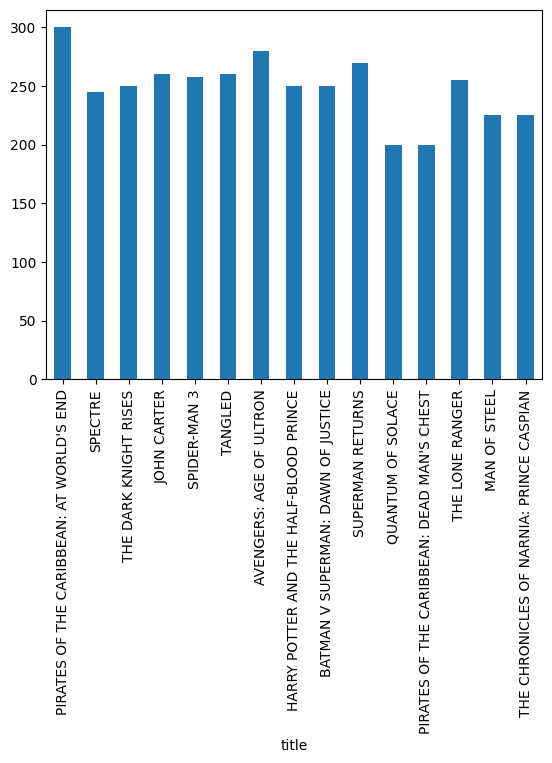

In [ ]:
# 8. ВИЗУАЛИЗИРОВАТЬ ДАННЫЕ
df_top = df.head(15).set_index('title') # Подготавливаем 15 первых фильмов для графика
df_top['budget_mln'].plot(kind='bar') # Строим столбчатую диаграмму (bar chart)
plt.show() # Отрисовываем график

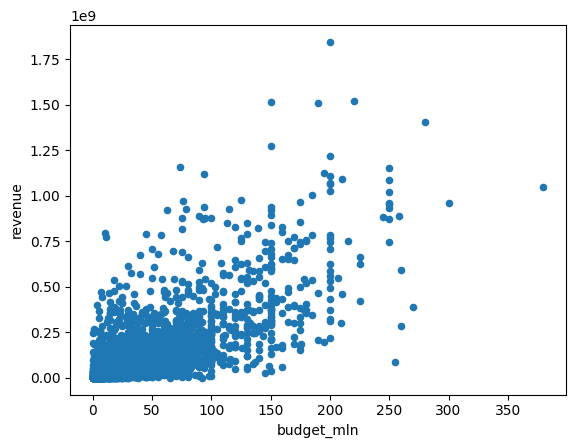

In [ ]:
df.plot(kind='scatter', x='budget_mln', y='revenue') # Строим точечный график через pandas
plt.show() # Отрисовываем график

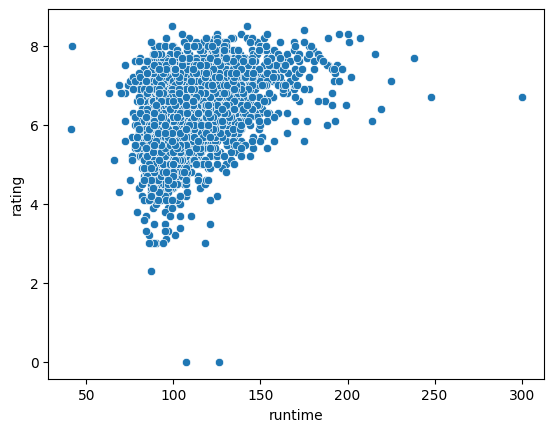

In [ ]:
sns.scatterplot(x='runtime', y='rating', data=df) # Строим точечный график через seaborn
plt.show() # Отрисовываем график

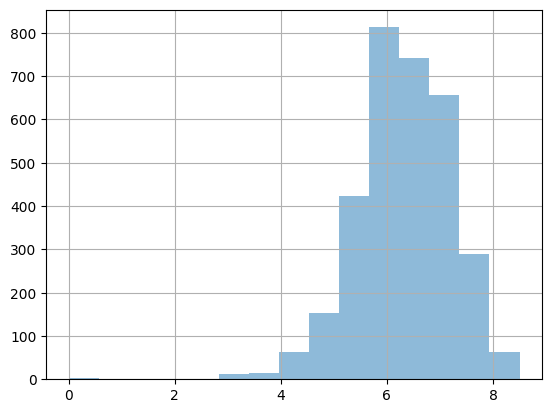

In [ ]:
df['rating'].hist(bins=15, alpha=0.5) # Строим гистограмму распределения оценок
plt.show() # Отрисовываем график

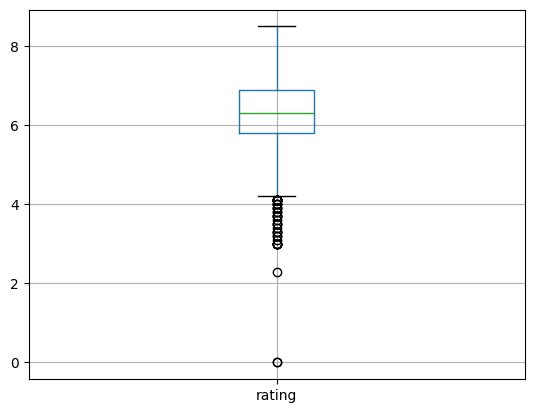

In [ ]:
df.boxplot(column='rating') # Строим ящик с усами для поиска выбросов в оценках
plt.show() # Отрисовываем график

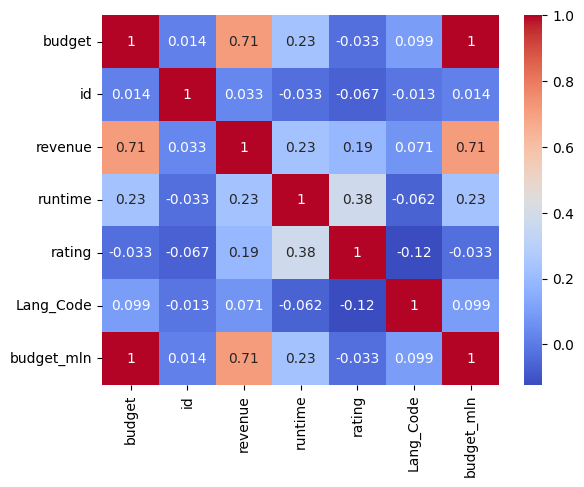

In [ ]:
# 9. КОРРЕЛЯЦИИ
numeric_cols = df.select_dtypes(include=['number']) # Отбираем только столбцы с цифрами
numeric_cols.corr() # Вычисляем матрицу корреляций
numeric_cols.corr().style.background_gradient(cmap='coolwarm') # Раскрашиваем матрицу (сработает в Jupyter)
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm') # Строим красивую тепловую карту (heatmap)
plt.show() # Отрисовываем график

In [ ]:
# 10. ГРУППИРОВКА И АГРЕГАЦИЯ
df.groupby('Lang_Code')['rating'].mean() # Группируем по коду языка и считаем средний рейтинг (groupby)
df.agg({'revenue': ['min', 'max']}) # Агрегируем (agg): находим минимум и максимум среди всех сборов
pd.pivot_table(df, values='rating', index='Lang_Code', aggfunc='mean') # Создаем сводную таблицу (pivot_table)

,rating
Lang_Code,
0,6.900000
2,6.600000
4,6.900000
5,7.255556
7,6.926667
8,7.800000
9,7.800000
10,6.942857
12,7.400000


In [ ]:
# 11. ЗАВИСИМОСТИ И ТАБЛИЦЫ СОПРЯЖЕННОСТЕЙ
# Создаем ручной DataFrame 2x2
df_fisher = pd.DataFrame([[300, 50], [100, 400]], columns=['Окупился', 'Не окупился'], index=['Длинный', 'Короткий'])
odds_ratio, p_value_fisher = fisher_exact(df_fisher.values) # Применяем тест Фишера
print('Отношение шансов:', odds_ratio) # Выводим отношение шансов
print('P-value Фишера:', p_value_fisher) # Выводим P-value

Отношение шансов: 24.0
P-value Фишера: 7.55271680143001e-86


In [ ]:
# Создаем реальную таблицу сопряженности (crosstab) для теста Хи-Квадрат
contingency = pd.crosstab(df['budget'] > 50000000, df['revenue'] > 100000000) # Большой бюджет против больших сборов
chi2, p_value_chi2, dof, expected = chi2_contingency(contingency) # Применяем Хи-Квадрат
print('Статистика Хи-квадрат:', chi2) # Выводим статистику - зависимость между переменными
print('P-value Хи-квадрат:', p_value_chi2) # Выводим P-value - насколько зависимость случайна (от 0.05)

Статистика Хи-квадрат: 845.7065774977922
P-value Хи-квадрат: 6.236892086115798e-186
